# Version with real data
Real data used. Temperature of 220 C. Tested on T=190 C. 
Output also n within range of [1.5 and 3.5].
Ea, A and n, are output at every time step; Ea and A are dependent only on the time.


In [72]:
import math
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import functools

def set_seed(s):
    import random
    random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    np.random.seed(s)
    # torch.backends.cudnn.deterministic = True
    # torch.backends.cudnn.benchmark = False

set_seed(0)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class ScaledSigmoid(nn.Module):
    def __init__(self, min_val, max_val):
        super(ScaledSigmoid, self).__init__()
        self.min_val = min_val
        self.max_val = max_val

    def forward(self, x):
        # Apply sigmoid to squish the output to (0, 1)
        x = torch.sigmoid(x)
        # Scale and shift to the desired range [min_val, max_val]
        return self.min_val + x * (self.max_val - self.min_val)

class EquationValue(nn.Module):
    def __init__(self, input_dims, min_val, max_val):
        super().__init__()
        assert min_val < max_val, "min_val must be less than max_val"
        self.min_val = min_val
        self.max_val = max_val
        self.scaled_sigmoid = ScaledSigmoid(min_val, max_val)
        self.input_dims = input_dims
        self.linear = nn.Linear(input_dims, 1)     

        # # Target a pre-activation range of approximately [-4, 4].
        # # If we assume inputs are roughly unit variance, then scale the weights:
        # weight_range = self.max_val / math.sqrt(input_dims)  # This is a heuristic value.
        # nn.init.uniform_(self.linear.weight, -weight_range, weight_range)
        
        # # Similarly, initialize biases to cover a wide range.
        # # Here we set biases uniformly over [-4,4].
        # nn.init.uniform_(self.linear.bias, self.min_val, self.max_val)  

    def forward(self, x):
        # Apply the linear layer
        x = self.linear(x)
        # Apply the scaled sigmoid activation function
        x = self.scaled_sigmoid(x)
        return x

class DiscoveryNet(nn.Module):
    def __init__(self, input_dim, output_dim, n_units=100, epochs=1000, loss = nn.MSELoss(), lr=1e-3, loss2=None, loss2_weight=0.1, patience=0) -> None:
        super().__init__()

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.epochs = epochs
        self.loss = loss
        self.loss2 = loss2
        self.loss2_weight = loss2_weight
        self.lr = lr 
        self.n_units = n_units
        self.patience = patience
    
        self.layers = nn.Sequential(
            nn.Linear(input_dim, self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
        )
        # self.out = nn.Linear(self.n_units, output_dim)

        self.d = EquationValue(self.n_units, 0, 1)
        self.Ea = EquationValue(self.n_units, 30000, 70000)
        self.A = EquationValue(self.n_units, 1e-5, 1e-1)  # 0.00001 to 0.1
        self.n = EquationValue(self.n_units, 1, 3) 
    
    def forward(self, x):
        h = self.layers(x)

        d = self.d(h)
        Ea = self.Ea(h)
        A = self.A(h)
        n = self.n(h)

        return torch.cat((d, Ea, A, n), dim=1)

    def fit(self, X, y, scaler=None):
        Xt = np_to_tensor(X)
        yt = np_to_tensor(y)

        optimiser = optim.Adam(self.parameters(), lr=self.lr)
        self.train()
        losses = []
        data_losses = []
        physic_losses = []
        for ep in range(self.epochs):
            optimiser.zero_grad()
            outputs = self.forward(Xt)

            d = outputs[:, 0].reshape(-1, 1)
            # d = scaler.inverse_transform(d).type(torch.float32) if scaler else d

            data_loss = self.loss(yt, d)
            if self.loss2:
                physic_loss = self.loss2_weight * self.loss2(self)
                loss = data_loss + physic_loss
                physic_losses.append(physic_loss.item())
            else:
                loss = data_loss
            data_losses.append(data_loss.item())

            loss.backward()
            optimiser.step()
            losses.append(loss.item())
            if ep % int(self.epochs / 10) == 0:
                if physic_losses:
                    physic_loss_avg = np.mean(physic_losses).item()
                    # print("Estimated Ea :", outputs[:, 1].reshape(-1, 1).mean().item())
                    # print("Estimated A :", outputs[:, 2].reshape(-1, 1).mean().item())
                    estimateds = f"Ea={outputs[:, 1].reshape(-1, 1).mean().item():.2f}, A={outputs[:, 2].reshape(-1, 1).mean().item():.2e}, n={outputs[:, 3].reshape(-1, 1).mean().item():.2f}"
                else:
                    physic_loss_avg = 0
                    estimateds = ""

                print(f"Epoch {ep}/{self.epochs}, loss: {np.mean(losses).item():.6f} - data_loss: {np.mean(data_losses).item():.6f} - physic_loss: {physic_loss_avg:.6f} - {estimateds}")
        return losses

    def predict(self, X):
        self.eval()
        out = self.forward(np_to_tensor(X))
        return out.detach().cpu().numpy()

def np_to_tensor(x):
    if isinstance(x, torch.Tensor) and x.device == DEVICE:
        return x
    elif isinstance(x, torch.Tensor):
        return x.to(DEVICE)
    elif isinstance(x, list):
        x = np.array(x)
    
    n_samples = len(x)
    return torch.from_numpy(x).to(torch.float).to(DEVICE).reshape(n_samples, -1)

In [83]:
# testing equationValue

etest = [EquationValue(10, 0, 1), EquationValue(10, 1, 3), EquationValue(10, 20000, 100000), EquationValue(10, 1e-5, 1e-1)]
# x = torch.randn(10, 10) ** 10
# print(x.min(), x.max())
for e in etest:
    tests = torch.cat([e(torch.randn(10, 10)) for i in range(50)])
    print(tests.min(), tests.max())


tensor(0.1593, grad_fn=<MinBackward1>) tensor(0.8628, grad_fn=<MaxBackward1>)
tensor(1.2727, grad_fn=<MinBackward1>) tensor(2.6866, grad_fn=<MaxBackward1>)
tensor(32511.8457, grad_fn=<MinBackward1>) tensor(86657.9453, grad_fn=<MaxBackward1>)
tensor(0.0136, grad_fn=<MinBackward1>) tensor(0.0866, grad_fn=<MaxBackward1>)


In [57]:
class TorchMinMaxScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.min_val = torch.tensor(0, dtype=torch.float32, device=DEVICE)
        self.max_val = torch.tensor(1, dtype=torch.float32, device=DEVICE)

    def fit_transform(self, data):
        # Compute min and max values from the data
        if not isinstance(data, torch.Tensor):
            data = torch.from_numpy(data)
        self.min_val = torch.min(data, dim=0)[0].to(device=DEVICE)
        self.max_val = torch.max(data, dim=0)[0].to(device=DEVICE)
        return self.transform(data)
    
    def transform(self, x):
        prev = None
        if not isinstance(x, torch.Tensor):
            x = torch.from_numpy(x).to(device=DEVICE)
        if x.device != DEVICE:
            prev  = x.device
            x = x.to(device=DEVICE)
        # Scale x to the range [0, 1]
        scaled = (x - self.min_val) / (self.max_val - self.min_val)
        if prev != DEVICE:
            scaled = scaled.to(device=prev)
        return scaled.type(torch.float32)
    
    def inverse_transform(self, x_scaled):
        # Inverse scaling: bring x_scaled back to original range
        return x_scaled * (self.max_val - self.min_val) + self.min_val

Text(0.5, 0, 'Time (s)')

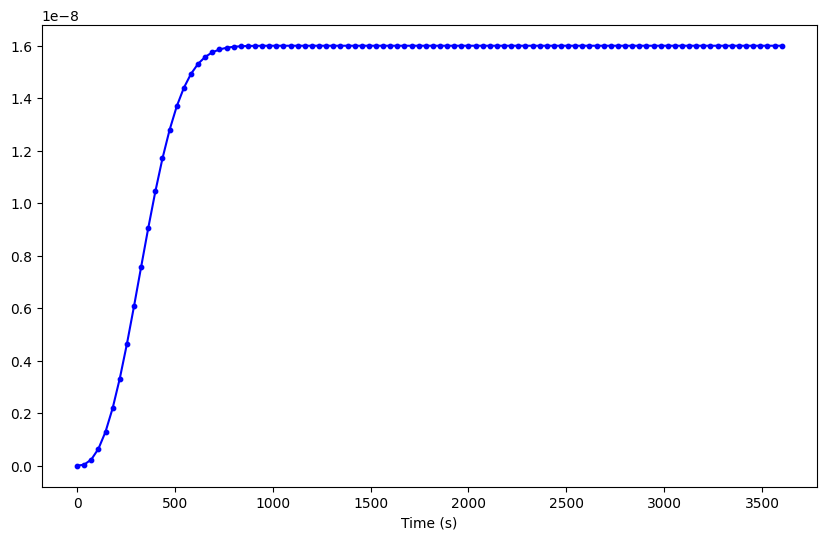

In [90]:
import numpy as np
import functools
import matplotlib.pyplot as plt

def avrami_law(t,Ea,R,T,A,n,r_max):
    K = A * np.exp(-Ea / (R * T))
    d = r_max * (1 - np.exp(-K * t**n))

    return d

np.random.seed(10)
A = 0.0015              # Increased to speed up transformation
Ea = 35000            # Lowered to increase reaction rate
T = 500               # Higher temp for faster growth
r_max = 16e-9         # Max radius in meters (30 nm)
n = 2.5
R = 8.314

TIME_MAX = 3600  # seconds

# Time array
times = np.linspace(0, TIME_MAX, 100)
eq = functools.partial(avrami_law, Ea=Ea, A=A, T=T, r_max=r_max, n=n, R=R)
values = eq(times)

plt.figure(figsize=(10, 6))
plt.plot(times, values, label='Avrami Law', color='blue')
plt.scatter(times, values, color='blue', s=10)
plt.xlabel('Time (s)')


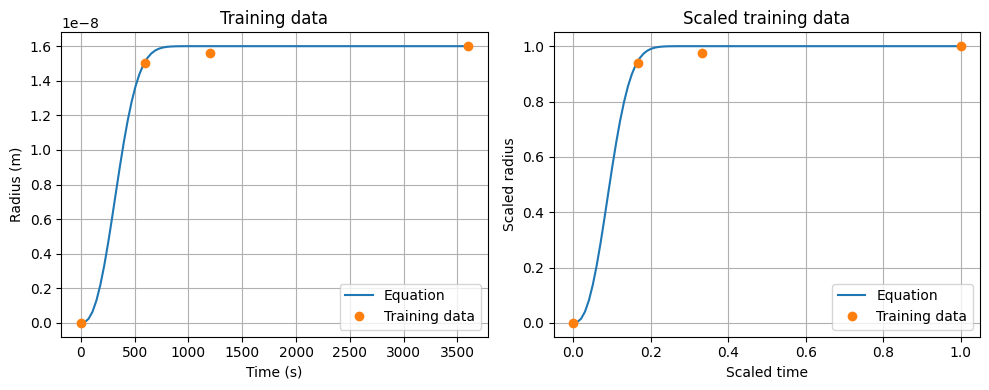

In [ ]:

TIME_MAX = 540 # seconds

# Time array
gt_times_X = np.linspace(0, TIME_MAX, 100)
eq = functools.partial(avrami_law, Ea=Ea, A=A, T=T, r_max=r_max, n=n, R=R)
gt_d_Y = eq(gt_times_X) # * 1e9


## REAL DATA
data220 = """T,time,d\n
220,0,0\n
220,10,15\n
220,20,15.6\n
220,60,16"""
data190 = """190,0,0\n
190,10,10.5\n
190,30,12.9\n
190,60,13.9"""

data = [[0,0], [4,42], [6,50], [8,53],[9,59]]
data = torch.tensor(data, dtype=torch.float32)
train_times_X = data[:, 0].reshape(-1, 1) * 60
train_d_Y = data[:, 1].reshape(-1, 1) * 1e-9


# Scale data
scaler_X = TorchMinMaxScaler()
scaler_Y = TorchMinMaxScaler()

# Fit and transform the training data
eq_times_X_scaled = scaler_X.fit_transform(gt_times_X.reshape(-1, 1)).type(torch.float32)
eq_d_Y_scaled = scaler_Y.fit_transform(gt_d_Y.reshape(-1, 1)).type(torch.float32)

# Transform test data using the already fitted scalers
train_times_X_scaled = scaler_X.transform(train_times_X.reshape(-1, 1)).type(torch.float32)
train_d_Y_scaled = scaler_Y.transform(train_d_Y.reshape(-1, 1)).type(torch.float32)


# Plot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(gt_times_X, gt_d_Y, label="Equation")
plt.plot(train_times_X, train_d_Y , 'o', label="Training data")
# noisy data
plt.grid()
plt.legend()
plt.title("Training data")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.subplot(1, 2, 2)
plt.plot(eq_times_X_scaled, eq_d_Y_scaled, label="Equation")
plt.plot(train_times_X_scaled.cpu().numpy(), train_d_Y_scaled.cpu().numpy() , 'o', label="Training data")
plt.grid()
plt.legend()
plt.title("Scaled training data")
plt.xlabel("Scaled time")
plt.ylabel("Scaled radius")
plt.tight_layout()
plt.show(block=False)

Epoch 0/30000, loss: 0.239272 - data_loss: 0.239272 - physic_loss: 0.000000 - 
Epoch 3000/30000, loss: 0.014969 - data_loss: 0.014969 - physic_loss: 0.000000 - 
Epoch 6000/30000, loss: 0.007486 - data_loss: 0.007486 - physic_loss: 0.000000 - 
Epoch 9000/30000, loss: 0.004991 - data_loss: 0.004991 - physic_loss: 0.000000 - 
Epoch 12000/30000, loss: 0.003744 - data_loss: 0.003744 - physic_loss: 0.000000 - 
Epoch 15000/30000, loss: 0.002995 - data_loss: 0.002995 - physic_loss: 0.000000 - 
Epoch 18000/30000, loss: 0.002496 - data_loss: 0.002496 - physic_loss: 0.000000 - 
Epoch 21000/30000, loss: 0.002139 - data_loss: 0.002139 - physic_loss: 0.000000 - 
Epoch 24000/30000, loss: 0.001872 - data_loss: 0.001872 - physic_loss: 0.000000 - 
Epoch 27000/30000, loss: 0.001664 - data_loss: 0.001664 - physic_loss: 0.000000 - 


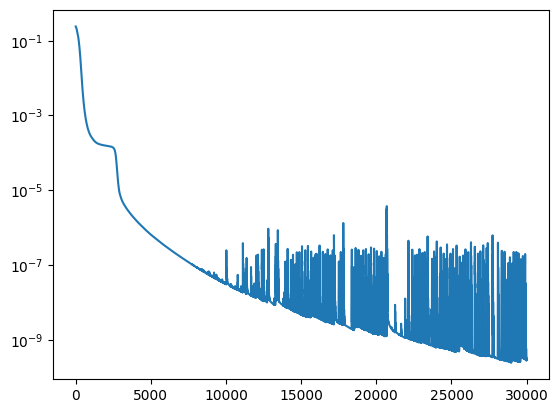

In [92]:

vanilla = DiscoveryNet(1, 3, loss2=None, loss2_weight=1, epochs=30000, lr=1e-4).to(DEVICE)
losses = vanilla.fit(train_times_X_scaled.to(DEVICE), train_d_Y_scaled.to(DEVICE), scaler_Y)
plt.plot(losses)
plt.yscale('log')

Epoch 0/100000, loss: 0.233490 - data_loss: 0.223071 - physic_loss: 0.010419 - Ea=50953.49, A=4.84e-02, n=2.05
Epoch 10000/100000, loss: 0.052130 - data_loss: 0.041457 - physic_loss: 0.010672 - Ea=62206.66, A=1.80e-02, n=1.52
Epoch 20000/100000, loss: 0.030892 - data_loss: 0.020818 - physic_loss: 0.010074 - Ea=51294.33, A=6.53e-02, n=2.53
Epoch 30000/100000, loss: 0.023432 - data_loss: 0.013931 - physic_loss: 0.009502 - Ea=50399.32, A=6.52e-02, n=2.50
Epoch 40000/100000, loss: 0.019661 - data_loss: 0.010486 - physic_loss: 0.009174 - Ea=50959.35, A=6.43e-02, n=2.51
Epoch 50000/100000, loss: 0.017392 - data_loss: 0.008420 - physic_loss: 0.008973 - Ea=51078.84, A=6.41e-02, n=2.52
Epoch 60000/100000, loss: 0.015876 - data_loss: 0.007042 - physic_loss: 0.008834 - Ea=50917.23, A=6.42e-02, n=2.52
Epoch 70000/100000, loss: 0.014787 - data_loss: 0.006058 - physic_loss: 0.008729 - Ea=50597.72, A=6.47e-02, n=2.51
Epoch 80000/100000, loss: 0.013993 - data_loss: 0.005321 - physic_loss: 0.008672 - E

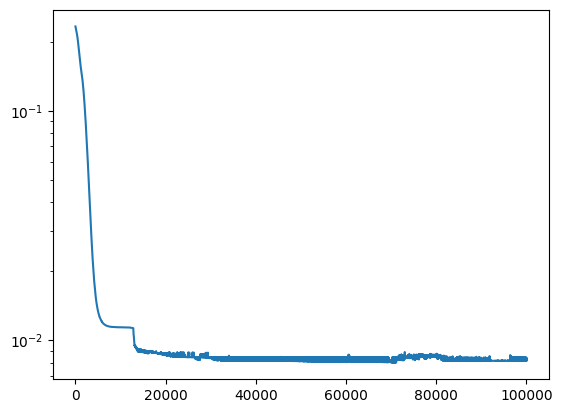

In [98]:


def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    

def physics_loss(model: torch.nn.Module):
    global PHYSICAL_LOSS_SCALING_FACTOR

    # Create time input for PINN
    ts = torch.linspace(0, 3600, steps=100, dtype=torch.float32).view(-1, 1).to(DEVICE).requires_grad_(True)
    ts_scaled = scaler_X.transform(ts)

    # Predict radius
    out = model(ts_scaled)
    d, Ea_net, A_net, n_net = out[:, 0], out[:, 1], out[:, 2], out[:, 3]  # [-1, 1] [0, 1]
    d = scaler_Y.inverse_transform(d)
    
    #Ea = torch.nn.functional.softplus(Ea_net) * 1e5
    #A = torch.nn.functional.softplus(A_net) * 1e-3
    # Ea = Ea_net * 1e5 
    # A = A_net * 1e-3

    Ea = Ea_net
    A = A_net
    n = n_net

    # Compute model's derivative wrt time
    dd = torch.autograd.grad(
        d, ts, 
        grad_outputs=torch.ones_like(d), 
        create_graph=True
    )[0]

    # Compute K
    K = A * torch.exp(-Ea / (R * T))
    # Theoretical Avrami derivative
    derived_eq = r_max * K * n * ts.pow(n - 1) * torch.exp(-K * ts.pow(n))

    pde_residual = dd - derived_eq
    # pde_residual = pde_residual * 1e12

    physical_loss = torch.mean(pde_residual**2)

    if PHYSICAL_LOSS_SCALING_FACTOR is None:
        # Get the maximum residual value as a float
        val = torch.max(physical_loss).item()
        # Compute the order-of-magnitude exponent. For a value like 5.23e-6,
        # math.log10(val) ≈ -5.28, and floor(-5.28) gives -6.
        exponent = -math.floor(math.log10(val))
        # Set the scaling factor as 10 raised to the computed exponent.
        # PHYSICAL_LOSS_SCALING_FACTOR = 10 ** exponent
        PHYSICAL_LOSS_SCALING_FACTOR = 1/abs(exponent)
        # PHYSICAL_LOSS_SCALING_FACTOR = 1e10
    # pde_residual = torch.pow(pde_residual, PHYSICAL_LOSS_SCALING_FACTOR)
    physical_loss = torch.pow(physical_loss, PHYSICAL_LOSS_SCALING_FACTOR)

    return physical_loss

# PHYSICAL_LOSS_SCALING_FACTOR = 1e-12
PHYSICAL_LOSS_SCALING_FACTOR = None

set_seed(0)
scaler_X = scaler_X.to(DEVICE)
scaler_Y = scaler_Y.to(DEVICE)
curr_train_times_X = train_times_X_scaled.to(DEVICE)
curr_train_d_Y = train_d_Y_scaled.to(DEVICE)


# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=150000, lr=1e-4).to(DEVICE)
# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=10000, lr=1e-4).to(DEVICE)
net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=0.1, epochs=100000, lr=1e-5).to(DEVICE)
# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=2, epochs=500000, lr=1e-5).to(DEVICE)
losses = net.fit(curr_train_times_X, curr_train_d_Y, scaler_Y)

plt.plot(losses)
plt.yscale('log')

Predicted A: 0.0709 std=0.009948, Guess A: 0.005  -  abs difference: 0.07
Predicted Ea: 50226.52 std=630.029602, Guess Ea: 60000  -  abs difference: 9773.48
Predicted n: 2.48 std=0.003073, Guess n: 2.5  -  abs difference: 59997.52


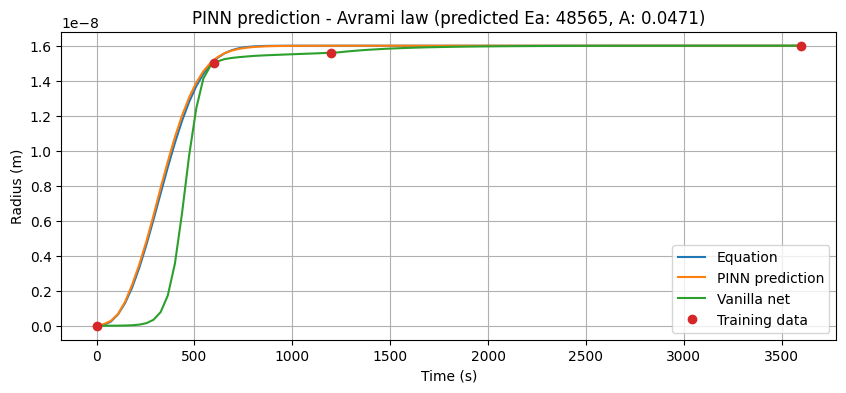

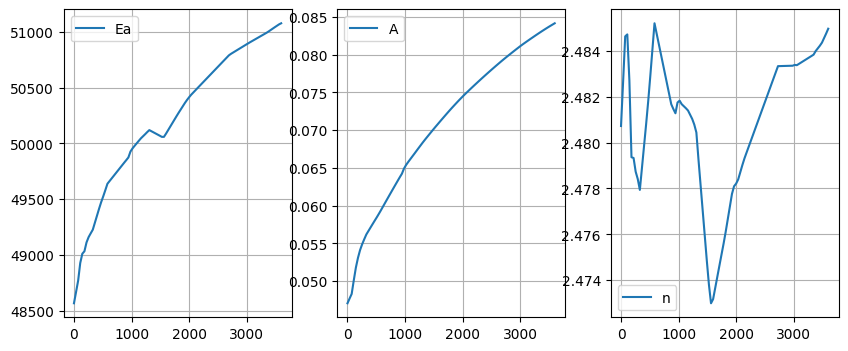

/tmp/ipykernel_709719/587605862.py:7: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = r_max * (1 - np.exp(-K * t**n))


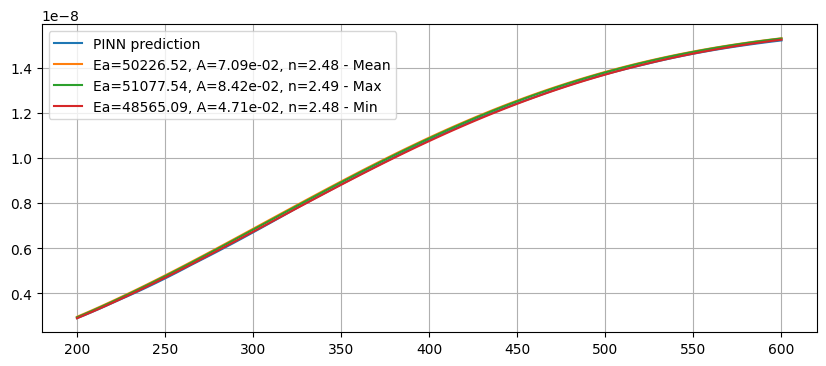

In [95]:
# plot the prediction on gt data

pred = net.predict(eq_times_X_scaled)
pred = torch.tensor(pred, dtype=torch.float32, device=DEVICE)
d, Ea_net, A_net, n_net = pred[:, 0], pred[:, 1], pred[:, 2], pred[:, 3]
d = scaler_Y.inverse_transform(d)
d = d.cpu().numpy()
Ea_net = Ea_net.cpu()
A_net = A_net.cpu()
n_net = n_net.cpu()

# expected:
A_expected = 5e-3   
Ea_expected = 60000 
n_expected = 2.5

Ea = Ea_net
A = A_net
n = n_net

print(f"Predicted A: {A.mean().item():.4f} std={A.std().item():.6f}, Guess A: {A_expected}  -  abs difference: {abs(A.mean().item() - A_expected):.2f}")
print(f"Predicted Ea: {Ea.mean().item():.2f} std={Ea.std().item():.6f}, Guess Ea: {Ea_expected}  -  abs difference: {abs(Ea.mean().item() - Ea_expected):.2f}")
print(f"Predicted n: {n_net.mean().item():.2f} std={n_net.std().item():.6f}, Guess n: {n_expected}  -  abs difference: {abs(n.mean().item() - Ea_expected):.2f}")

vanilla_pred = vanilla.predict(eq_times_X_scaled)
vanilla_pred = torch.tensor(vanilla_pred, dtype=torch.float32, device=DEVICE)
vanilla_d = vanilla_pred[:, 0]
vanilla_d = scaler_Y.inverse_transform(vanilla_d)
vanilla_d = vanilla_d.cpu().numpy()
plt.figure(figsize=(10, 4))
# plt.subplot(1, 2, 1)
plt.plot(gt_times_X, gt_d_Y, label="Equation")
plt.plot(gt_times_X, d, label="PINN prediction")
plt.plot(gt_times_X, vanilla_d, label="Vanilla net")
# plot train data
plt.plot(train_times_X, train_d_Y , 'o', label="Training data")
plt.title(f"PINN prediction - Avrami law (predicted Ea: {Ea.min().item():.0f}, A: {A.min().item():.4f})")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.grid()
plt.legend()
plt.show()


# plot all Ea and A values
plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.plot(gt_times_X, Ea, label="Ea")
plt.legend()
plt.grid()
plt.subplot(1, 3, 2)
plt.plot(gt_times_X, A, label="A")
plt.legend()
plt.grid()
plt.subplot(1, 3, 3)
plt.plot(gt_times_X, n, label="n")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(10, 4))
# plot avrami eq using predicted A and Ea
times = torch.linspace(200, 600, 100)
# times = torch.linspace(350, 400, 100)
# times = torch.linspace(0, TIME_MAX, 100)

times_s = scaler_X.transform(times.reshape(-1, 1)).type(torch.float32).to(DEVICE)
times_s = times_s.reshape(-1, 1)
pred = net.predict(times_s)
pred = torch.tensor(pred, dtype=torch.float32, device=DEVICE)
d, Ea_net, A_net, pred_n = pred[:, 0], pred[:, 1], pred[:, 2], pred[:, 3]
d = scaler_Y.inverse_transform(d)
d = d.cpu().numpy()
plt.plot(times.cpu().numpy(), d, label="PINN prediction")


eq_temp = functools.partial(avrami_law, A=A.mean().item(), Ea=Ea.mean().item(), T=T, r_max=r_max, n=pred_n.mean().item(), R=R)
eq_d_Y = eq_temp(times)
plt.plot(times, eq_d_Y, label=f"Ea={Ea.mean().item():.2f}, A={A.mean().item():.2e}, n={pred_n.mean().item():.2f} - Mean")

eq_temp = functools.partial(avrami_law, A=A.max().item(), Ea=Ea.max().item(), T=T, r_max=r_max, n=pred_n.max().item(), R=R)
eq_d_Y = eq_temp(times)
plt.plot(times, eq_d_Y, label=f"Ea={Ea.max().item():.2f}, A={A.max().item():.2e}, n={pred_n.max().item():.2f} - Max")

eq_temp = functools.partial(avrami_law, A=A.min().item(), Ea=Ea.min().item(), T=T, r_max=r_max, n=pred_n.min().item(), R=R)
eq_d_Y = eq_temp(times)
plt.plot(times, eq_d_Y, label=f"Ea={Ea.min().item():.2f}, A={A.min().item():.2e}, n={pred_n.min().item():.2f} - Min")

# eq_temp = functools.partial(avrami_law, A=4e-2, Ea=47000, T=T, r_max=r_max, n=n, R=R)
# eq_d_Y = eq_temp(times)
# plt.plot(times, eq_d_Y, label=f"Ea=47000, A=4e-2 - Test")


# plt.scatter(train_times_X, train_d_Y , label="Training data", color='red')

plt.legend()
plt.grid()
plt.show()


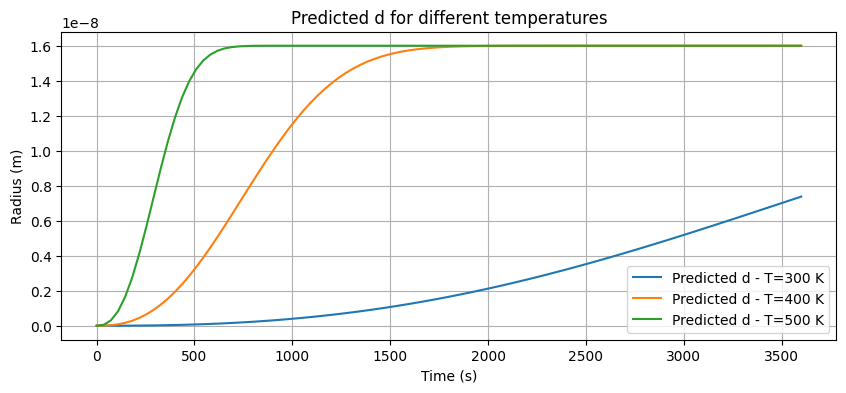

In [ ]:

eq_temp = functools.partial(avrami_law, A=A.min().item(), Ea=Ea.min().item(), r_max=r_max, n=n, R=R)
max_time = 3600 # 1 hour

times = np.linspace(0, max_time, 100)

plt.figure(figsize=(10, 4))
for temp in [300, 400, 500]:
    expeced_d = eq_temp(times, T=temp)
    plt.plot(times, expeced_d, label=f"Predicted d - T={temp} K")

plt.title("Predicted d for different temperatures")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.legend()
plt.grid()
plt.show()


## ONE WAY
t = [0, 1, 2, ...] # seconds for a total of N steps
d, Ea, A = nn(t)

at the end you have
- d -> [N]
- Ea -> [N] mean() std()
- A -> [N] mean() std()
- Ea and A uncertainty (std) -> DEPENDENT ON THE TIME

## SECOND WAY
t = [0, 1, 2, ...] # seconds for a total of N steps
d = nn(t)
Ea = nn.Ea # learned 
A = nn.A # learned 

- d -> [N]
- NO UNCERTAINTY IN Ea
- INDEPENDENT FROM THE TIME

/tmp/ipykernel_709719/587605862.py:7: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = r_max * (1 - np.exp(-K * t**n))


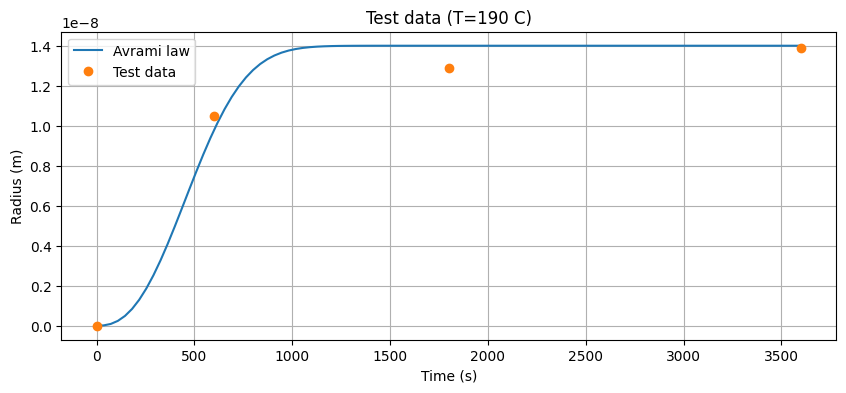

In [97]:
test_T = 190 + 273.15
test_data = [
    [0,0],
    [10*60,10.5],
    [30*60,12.9],
    [60*60,13.9]
]
test_times = torch.linspace(0, 3600, 100)
test_data = torch.tensor(test_data, dtype=torch.float32)
test_r_max = 14e-9

predicted_Ea = Ea.mean().item()
predicted_A = A.mean().item()
predicted_n = n.mean().item()

plt.figure(figsize=(10, 4))
eq_test = functools.partial(avrami_law, A=predicted_A, Ea=predicted_Ea, r_max=test_r_max, n=predicted_n, R=R)
law = eq_test(test_times, T=test_T)
plt.plot(test_times, law, label="Avrami law")
plt.plot(test_data[:, 0], test_data[:, 1] * 1e-9, 'o', label="Test data")
plt.title("Test data (T=190 C)")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.legend()
plt.grid()
plt.show()
